# 1 Nhập dữ liệu, thống kê thông tin cơ bản và xử lý dữ liệu bị thiếu

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn import metrics
import warnings
warnings.filterwarnings('ignore')

# 1. Nhập dữ liệu và thống kê cơ bản
data = pd.read_csv('Mall_Customers.csv')
print("--- Thông tin tổng quan ---")
display(data.head())
data.info()

print("\n--- Kiểm tra dữ liệu bị thiếu ---")
print(data.isnull().sum())

# Xử lý dữ liệu bị thiếu (nếu có)
data = data.dropna().reset_index(drop=True)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
--- Thông tin tổng quan ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

--- Kiểm tra dữ liệu bị thiếu ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# 2 Sử dụng biểu đồ tần suất (Histogram) để biểu diễn phân phối

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


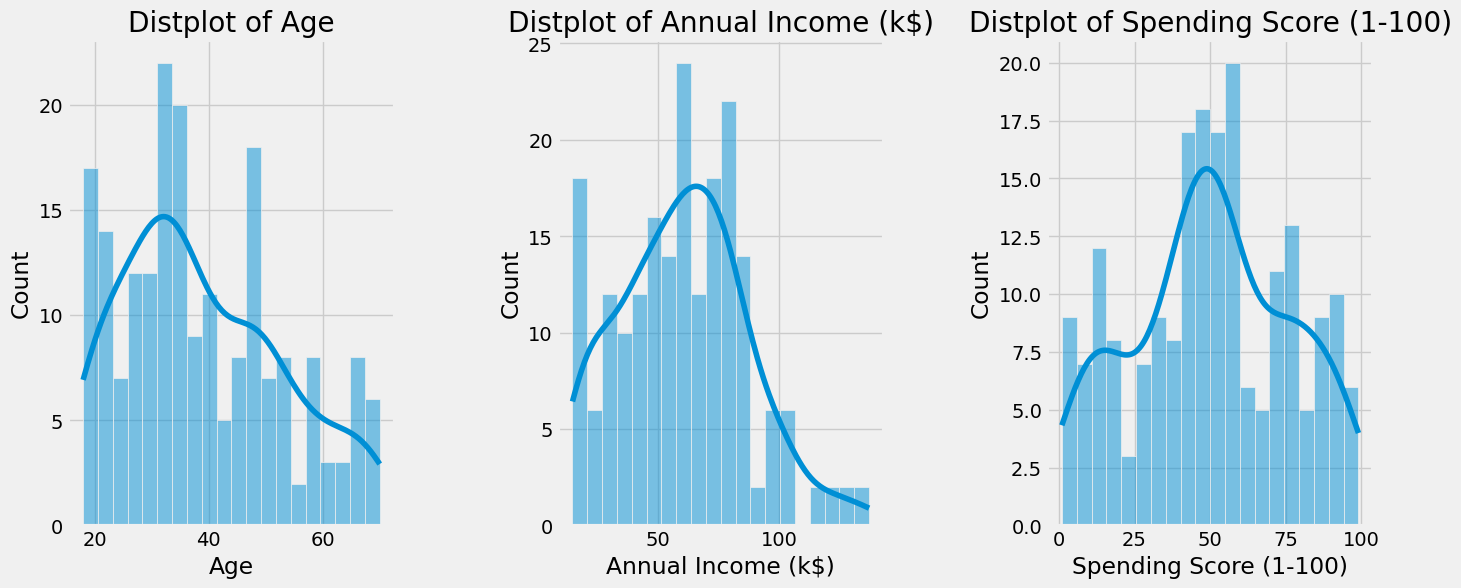

In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.style.use('fivethirtyeight')
plt.figure(figsize=(15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True)
    plt.title('Distplot of {}'.format(x))
plt.show()

# 3 Thống kê số mẫu dữ liệu theo thuộc tính Giới tính

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


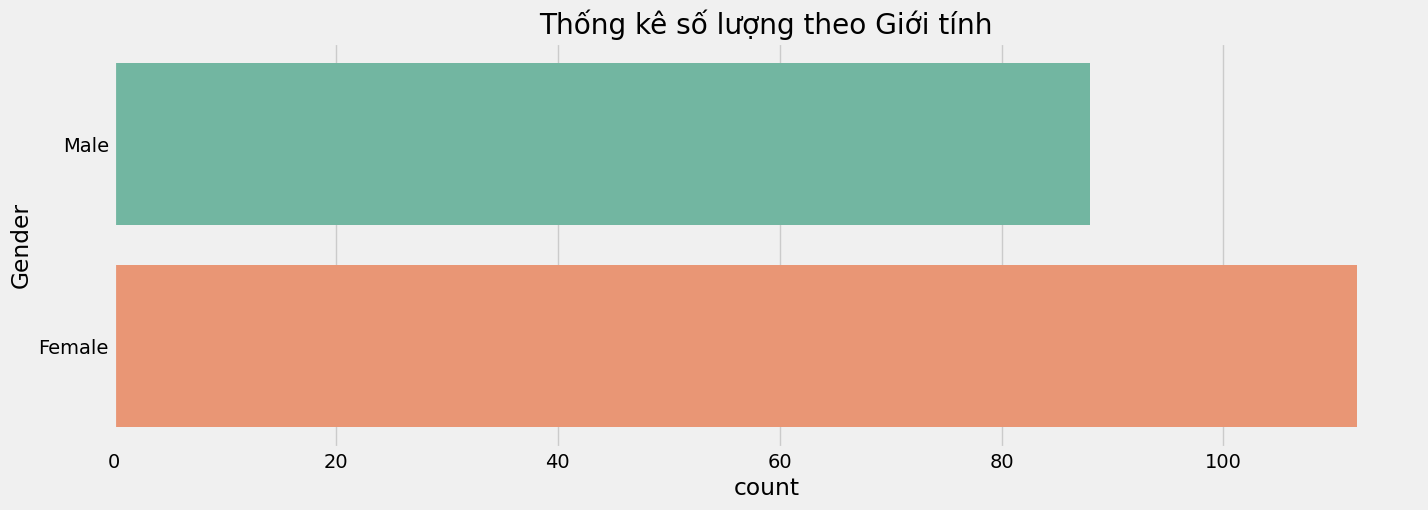

Gender
Female    112
Male       88
Name: count, dtype: int64


In [3]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(15, 5))
sns.countplot(y='Gender', data=data, palette='Set2')
plt.title('Thống kê số lượng theo Giới tính')
plt.show()

print(data['Gender'].value_counts())

# 4 Sử dụng biểu đồ phân tán (Scatter plot) khảo sát Tuổi và Thu nhập theo Giới tính

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


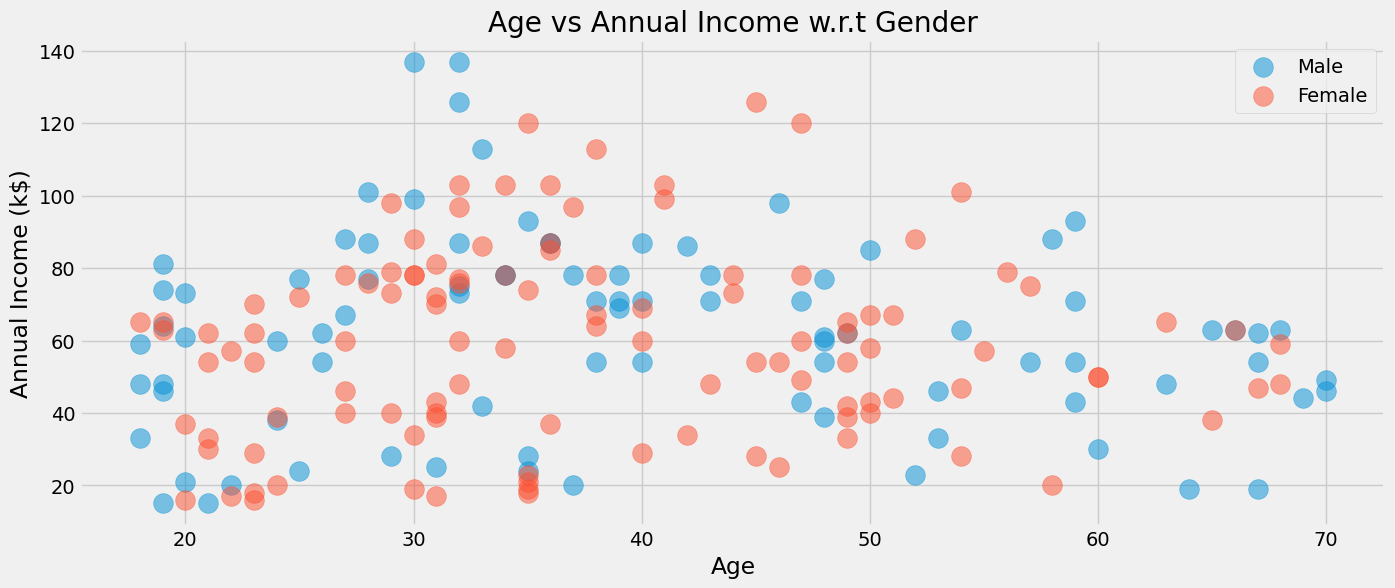

In [4]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Age', y='Annual Income (k$)',
                data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income w.r.t Gender')
plt.legend()
plt.show()

# 5 Khảo sát Thu nhập hằng năm và Số điểm mua sắm theo Giới tính

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


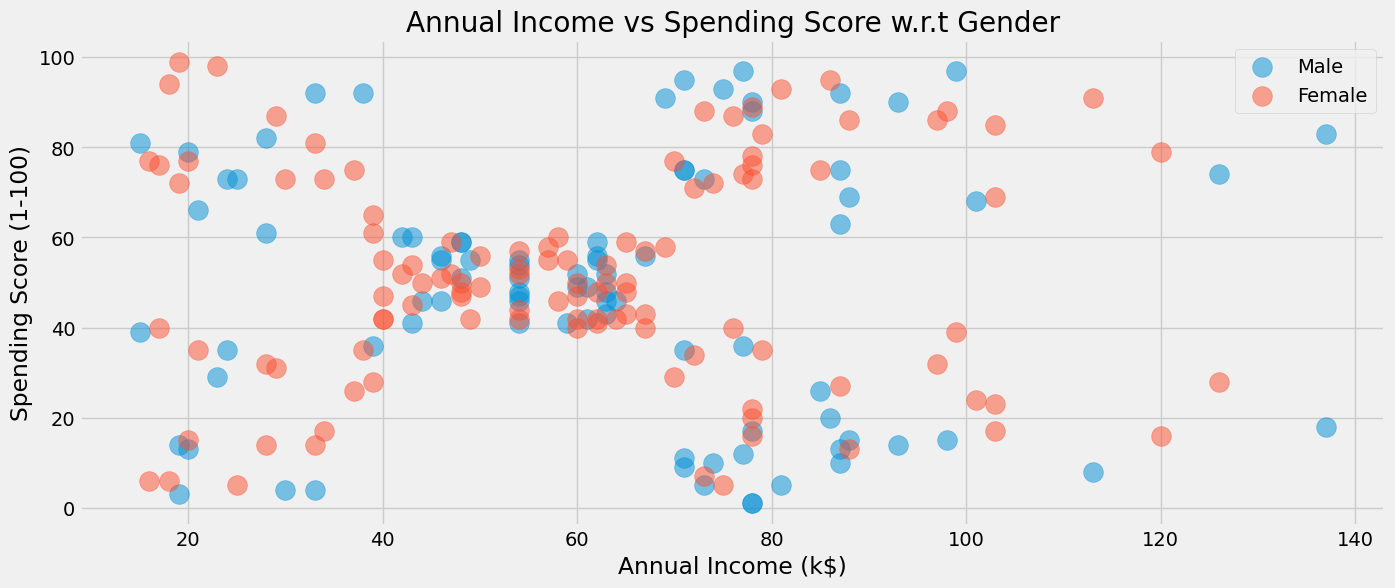

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)',
                data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

# 6 Gom cụm Tuổi và Số điểm mua sắm (Dùng phương pháp khuỷu tay - Elbow Method)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


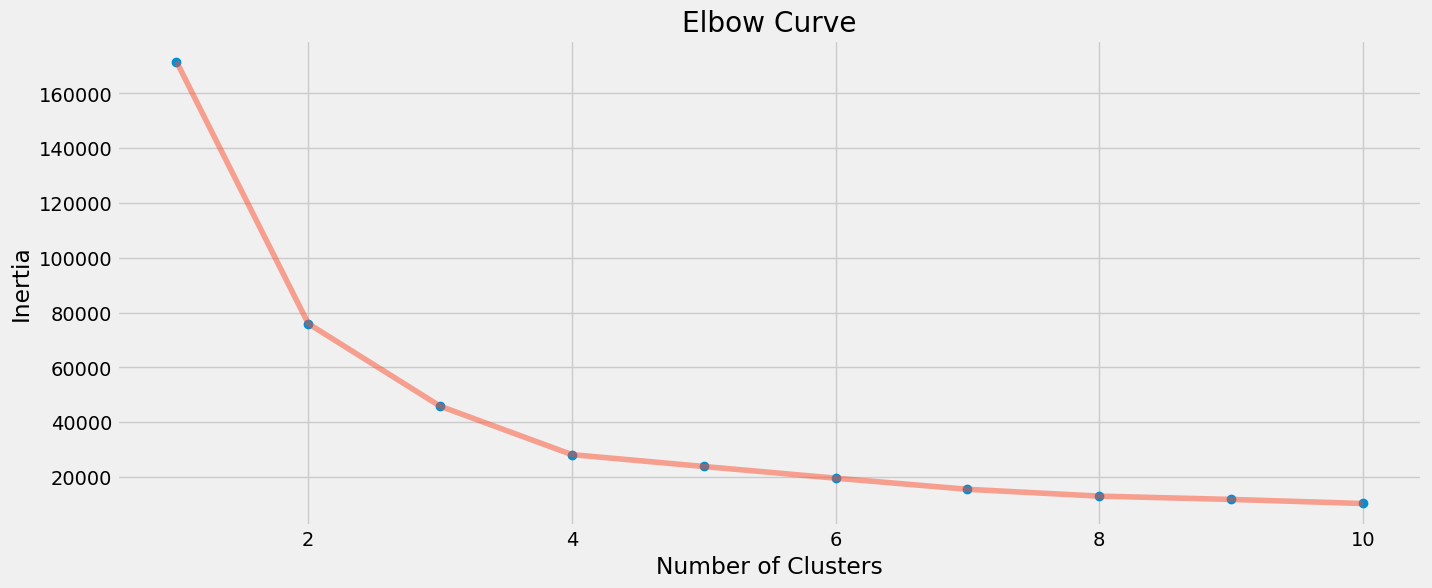

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

X1 = data[['Age', 'Spending Score (1-100)']].iloc[:, :].values
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)

# Vẽ biểu đồ Elbow Curve
plt.figure(figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Curve')
plt.show()

# Xác định số cụm tối ưu k = 4 và tiến hành gom cụm
algorithm1 = KMeans(n_clusters=4, init='random', random_state=42)
algorithm1.fit(X1)
labels1 = algorithm1.labels_
centroids1 = algorithm1.cluster_centers_

# 7 Biểu diễn kết quả gom cụm trên bảng biểu đồ (2D)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


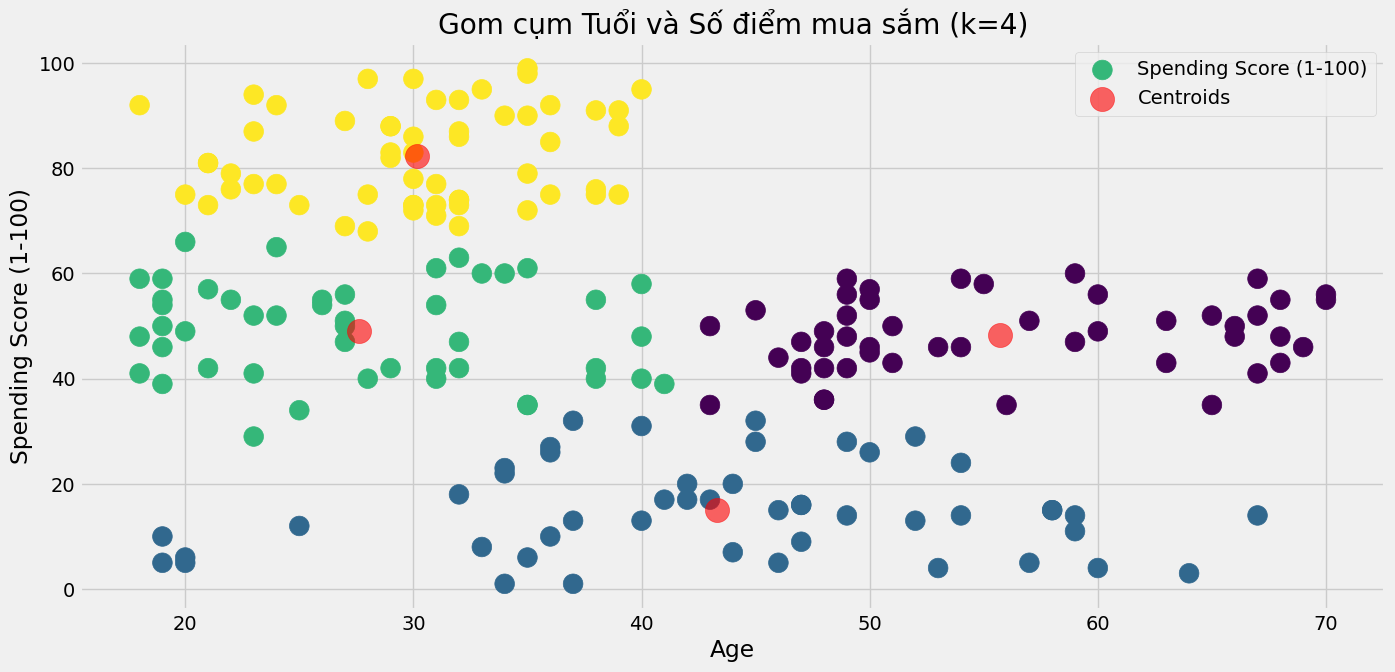

In [7]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

plt.figure(figsize=(15, 7))
plt.clf()
plt.scatter(x='Age', y='Spending Score (1-100)', data=data, c=labels1, s=200, cmap='viridis')
plt.scatter(centroids1[:, 0], centroids1[:, 1], s=300, c='red', alpha=0.6, label='Centroids')
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.title('Gom cụm Tuổi và Số điểm mua sắm (k=4)')
plt.legend()
plt.show()

# 8 Đánh giá kết quả gom cụm bằng Hệ số Dáng điệu (Silhouette coefficient)

In [8]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

score1 = metrics.silhouette_score(X1, labels1, metric='euclidean')
print(f"Hệ số Silhouette Coefficient (Tuổi & Spending Score): {score1:.4f}")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Hệ số Silhouette Coefficient (Tuổi & Spending Score): 0.4997


# 9 Gom cụm theo các thuộc tính khác (Thu nhập & Số điểm, hoặc 3D Tuổi, Thu nhập, Số điểm)

In [9]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import plotly as py
import plotly.graph_objs as go

# --- 9.1. Gom cụm Thu nhập hằng năm và Số điểm mua sắm ---
X2 = data[['Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
algorithm2 = KMeans(n_clusters=5, init='random', random_state=42)
algorithm2.fit(X2)
labels2 = algorithm2.labels_
centroids2 = algorithm2.cluster_centers_

print(f"Silhouette (Annual Income & Spending Score): {metrics.silhouette_score(X2, labels2, metric='euclidean'):.4f}")

# --- 9.2. Gom cụm 3 thuộc tính (Tuổi, Thu nhập, Số điểm) và vẽ biểu đồ 3D ---
X3 = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
algorithm3 = KMeans(n_clusters=5, init='random', random_state=42)
algorithm3.fit(X3)
labels3 = algorithm3.labels_

data['label3'] = labels3
print(f"Silhouette (3 chiều Age, Income, Spending): {metrics.silhouette_score(X3, labels3, metric='euclidean'):.4f}")

# Vẽ biểu đồ 3D tương tác bằng Plotly
trace1 = go.Scatter3d(
    x=data['Age'],
    y=data['Spending Score (1-100)'],
    z=data['Annual Income (k$)'],
    mode='markers',
    marker=dict(color=data['label3'], size=10, colorscale='Viridis', opacity=0.8)
)
dat = [trace1]
layout = go.Layout(
    title='Clusters 3D (Age, Spending Score, Annual Income)',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    )
)
fig = go.Figure(data=dat, layout=layout)
py.offline.iplot(fig)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Silhouette (Annual Income & Spending Score): 0.5539
Silhouette (3 chiều Age, Income, Spending): 0.4443
